In [1]:
!pip install imbalanced-learn xlrd

In [3]:
!ls

default_of_credit_card_clients.xls.xls	sample_data


In [4]:
"""
CPCS 433 - Credit Card Default Prediction
Pair A: Logistic Regression
Experiments: Baseline | SMOTE | class_weight | Threshold tuning

Install:  pip install pandas scikit-learn imbalanced-learn openpyxl
Dataset:  download "default of credit card clients" from UCI
          (https://archive.ics.uci.edu/dataset/350) and put the file
          next to this script as  default_of_credit_card_clients.xls
"""
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
from imblearn.pipeline import Pipeline          # NOT sklearn's Pipeline
from imblearn.over_sampling import SMOTE

SEED = 42
DATA_FILE = "default_of_credit_card_clients.xls"

# ---------------------------------------------------------------- 1. Load
df = pd.read_excel(DATA_FILE, header=1)          # row 0 is a title row in the UCI file
df = df.rename(columns={"PAY_0": "PAY_1",
                        "default payment next month": "default"})
df = df.drop(columns=["ID"])

# ---------------------------------------------------------------- 2. Clean
# Undocumented category codes -> merge into "others"
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
print("Duplicates:", df.duplicated().sum(), "| Missing:", df.isna().sum().sum())
print(df["default"].value_counts(normalize=True).round(4))

# One-hot for nominal columns (PAY_x stay numeric: they are ordinal)
df = pd.get_dummies(df, columns=["SEX", "EDUCATION", "MARRIAGE"], drop_first=True)

X = df.drop(columns=["default"])
y = df["default"]

# ---------------------------------------------------------------- 3. Shared split
# Both pairs MUST use the same split. Save the indices and share the file.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
pd.Series(X_train.index).to_csv("train_idx.csv", index=False)
pd.Series(X_test.index).to_csv("test_idx.csv", index=False)

# ---------------------------------------------------------------- 4. Helpers
def evaluate(name, model, X_te, y_te, threshold=0.5):
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return {
        "Experiment": name,
        "Threshold": round(threshold, 2),
        "Accuracy": round(accuracy_score(y_te, pred), 2),
        "Precision": round(precision_score(y_te, pred, zero_division=0), 2),
        "Recall": round(recall_score(y_te, pred), 2),
        "F1": round(f1_score(y_te, pred), 2),
        "ROC-AUC": round(roc_auc_score(y_te, proba), 2),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

def make_lr(class_weight=None):
    return LogisticRegression(max_iter=1000, C=1.0,
                              class_weight=class_weight, random_state=SEED)

results = []

# ---------------------------------------------------------------- 5. Experiments
# E1: Baseline (scaling only)
base = Pipeline([("scale", StandardScaler()), ("clf", make_lr())])
base.fit(X_train, y_train)
results.append(evaluate("E1 Baseline", base, X_test, y_test))

# E2: SMOTE (applied inside the pipeline => only on training data)
smote = Pipeline([("scale", StandardScaler()),
                  ("smote", SMOTE(random_state=SEED)),
                  ("clf", make_lr())])
smote.fit(X_train, y_train)
results.append(evaluate("E2 SMOTE", smote, X_test, y_test))

# E3: class_weight='balanced'
cw = Pipeline([("scale", StandardScaler()),
               ("clf", make_lr(class_weight="balanced"))])
cw.fit(X_train, y_train)
results.append(evaluate("E3 class_weight", cw, X_test, y_test))

# E4: Threshold tuning on the baseline model.
# The threshold is chosen using cross-validated probabilities on the TRAIN set
# only (never on the test set) to avoid leakage.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = cross_val_predict(base, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.arange(0.10, 0.90, 0.01)
best_t = max(thresholds, key=lambda t: f1_score(y_train, (oof >= t).astype(int)))
print("Best threshold (CV on train, max F1):", round(best_t, 2))
results.append(evaluate("E4 Threshold tuning", base, X_test, y_test, threshold=best_t))

# ---------------------------------------------------------------- 6. Report
out = pd.DataFrame(results)
print("\n", out.to_string(index=False))
out.to_csv("pair_a_results.csv", index=False)

Duplicates: 35 | Missing: 0
default
0    0.7788
1    0.2212
Name: proportion, dtype: float64
Best threshold (CV on train, max F1): 0.29

          Experiment  Threshold  Accuracy  Precision  Recall   F1  ROC-AUC   TN   FP   FN  TP
        E1 Baseline       0.50      0.81       0.69    0.24 0.36     0.71 4530  143 1003 324
           E2 SMOTE       0.50      0.67       0.36    0.64 0.46     0.71 3163 1510  479 848
    E3 class_weight       0.50      0.68       0.37    0.63 0.46     0.71 3234 1439  490 837
E4 Threshold tuning       0.29      0.79       0.54    0.47 0.50     0.71 4132  541  704 623


In [5]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(base, {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
                    scoring="roc_auc", cv=cv)
grid.fit(X_train, y_train)

print("Best C:", grid.best_params_)
print(pd.DataFrame(grid.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]])

Best C: {'clf__C': 10}
   param_clf__C  mean_test_score  std_test_score
0         0.001         0.722422        0.012167
1         0.010         0.726960        0.011743
2         0.100         0.727221        0.011629
3         1.000         0.727235        0.011620
4        10.000         0.727241        0.011611
5       100.000         0.727240        0.011608


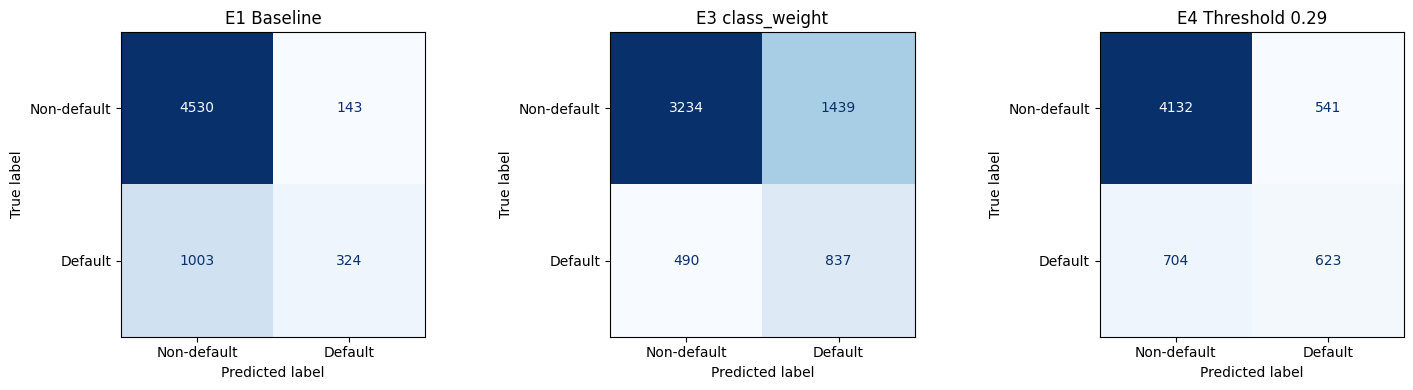

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model, t) in zip(axes, [("E1 Baseline", base, 0.5),
                                       ("E3 class_weight", cw, 0.5),
                                       ("E4 Threshold 0.29", base, best_t)]):
    pred = (model.predict_proba(X_test)[:, 1] >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Non-default", "Default"],
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("pair_a_confusion_matrices.png", dpi=300)
plt.show()